# 4. RL Training Curves

Two parts:

1. **Saved multi-seed runs** (`results/grid_b08/`): PPO and SAC trained with
   `examples/train_agent.py` on the default scenario (3x3 grid, synthetic traffic,
   `bandwidth_budget=0.8`), five training seeds each. This part only reads the saved
   CSV files, so it shows exactly what those runs produced.
2. **A short live run** on the real packet-capture trace, trained inside this notebook,
   so you can watch a learning curve being produced. It is deliberately short and is
   not the headline result.

Seed protocol: training envs draw fresh traffic every episode; learning curves use
validation seeds (1000+); final tables use test seeds (2000+) that neither training
nor the curves saw.

In [1]:
import sys, os
REPO_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
os.chdir(REPO_ROOT)

import time
from argparse import Namespace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from carla_gym.utils.stats import ci95
plt.rcParams["figure.dpi"] = 100
RESULTS = "results/grid_b08"

## Part 1: saved multi-seed PPO and SAC runs

In [2]:
import glob, re
finals, curves = [], []
for d in sorted(glob.glob(f"{RESULTS}/*_seed*")):
    m = re.fullmatch(r"(\w+?)_seed(\d+)", os.path.basename(d))
    if m and os.path.exists(f"{d}/final_eval.csv"):
        algo, seed = m.group(1).upper(), int(m.group(2))
        finals.append(pd.read_csv(f"{d}/final_eval.csv").assign(algo=algo, train_seed=seed))
        curves.append(pd.read_csv(f"{d}/eval_curve.csv").assign(algo=algo, train_seed=seed))
finals, curves = pd.concat(finals), pd.concat(curves)
ALGOS = sorted(finals["algo"].unique())
print({a: sorted(finals[finals.algo == a].train_seed.unique().tolist()) for a in ALGOS})
print({a: int(curves[curves.algo == a].timesteps.max()) for a in ALGOS}, "timesteps")

{'PPO': [0, 1, 2, 3, 4], 'SAC': [0, 1, 2, 3, 4]}
{'PPO': 500000, 'SAC': 100000} timesteps


In [3]:
rows = []
for algo in ALGOS:
    per_seed = finals[(finals.algo == algo) & (finals.policy == algo)].groupby("train_seed")["reward"].mean()
    rows.append({"policy": algo, "kind": "RL agent", "reward": per_seed.mean(), "ci95": ci95(per_seed),
                 "n": len(per_seed), "CI over": "training seeds"})
one = finals[(finals.algo == ALGOS[0]) & (finals.train_seed == finals[finals.algo == ALGOS[0]].train_seed.min())]
for name, g in one[~one.policy.isin(ALGOS)].groupby("policy"):
    rows.append({"policy": name, "kind": "baseline", "reward": g["reward"].mean(), "ci95": ci95(g["reward"]),
                 "n": len(g), "CI over": "test episodes"})
table = pd.DataFrame(rows).sort_values("reward", ascending=False).set_index("policy")
table.round(3)

,kind,reward,ci95,n,CI over
policy,,,,,
PPO,RL agent,0.494,0.013,5,training seeds
queue_proportional,baseline,0.404,0.024,10,test episodes
congestion_aware,baseline,0.386,0.021,10,test episodes
SAC,RL agent,0.383,0.028,5,training seeds
load_aware_routing,baseline,0.378,0.026,10,test episodes
max_bandwidth,baseline,0.317,0.030,10,test episodes
random,baseline,-0.908,0.026,10,test episodes
min_bandwidth,baseline,-1.803,0.008,10,test episodes


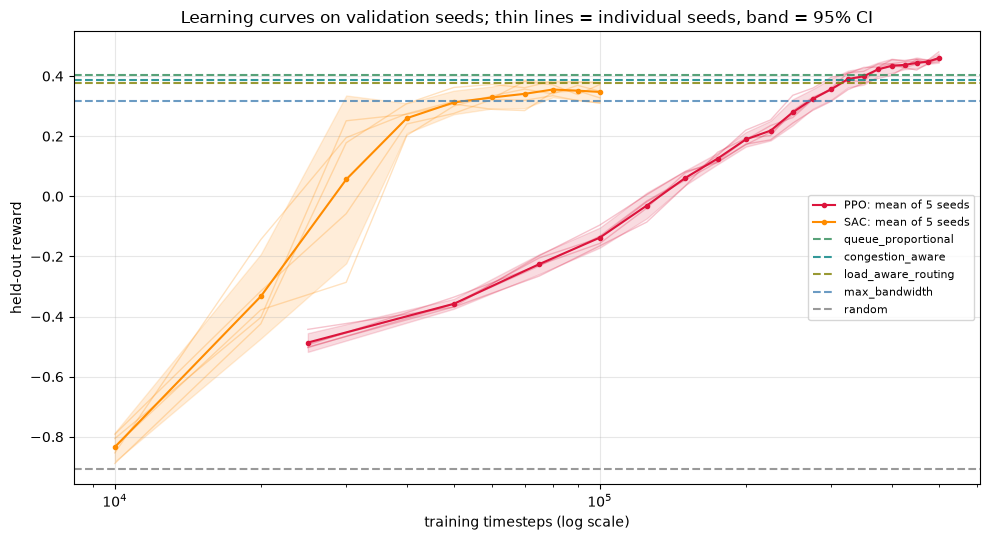

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for algo, color in zip(ALGOS, ["crimson", "darkorange", "purple"]):
    sub = curves[curves.algo == algo]
    for _, run in sub.groupby("train_seed"):
        ax.plot(run["timesteps"], run["reward_mean"], color=color, alpha=0.25, lw=1)
    g = sub.groupby("timesteps")["reward_mean"]
    mean, band = g.mean(), g.apply(ci95)
    ax.plot(mean.index, mean.values, color=color, marker="o", ms=3, label=f"{algo}: mean of {sub.train_seed.nunique()} seeds")
    ax.fill_between(mean.index, mean - band, mean + band, color=color, alpha=0.15)
styles = {"queue_proportional": "seagreen", "congestion_aware": "teal", "load_aware_routing": "olive",
          "max_bandwidth": "steelblue", "random": "gray"}
for name, color in styles.items():
    ax.axhline(table.loc[name, "reward"], ls="--", color=color, alpha=0.8, label=name)
ax.set_xscale("log")
ax.set_xlabel("training timesteps (log scale)")
ax.set_ylabel("held-out reward")
ax.set_title("Learning curves on validation seeds; thin lines = individual seeds, band = 95% CI")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [5]:
best_baseline = table[table.kind == "baseline"]["reward"].idxmax()
bb = table.loc[best_baseline]
for algo in ALGOS:
    first = curves[curves.algo == algo].groupby("timesteps")["reward_mean"].mean().iloc[0]
    r = table.loc[algo]
    gap = r["reward"] - bb["reward"]
    if abs(gap) <= r["ci95"] + bb["ci95"]:
        verdict = "statistically indistinguishable from"
    else:
        verdict = "above" if gap > 0 else "below"
    print(f"{algo}: first checkpoint {first:+.3f} -> test reward {r['reward']:+.3f} +/- {r['ci95']:.3f}; "
          f"{verdict} the best baseline ({best_baseline}, {bb['reward']:+.3f} +/- {bb['ci95']:.3f}); "
          f"random = {table.loc['random', 'reward']:+.3f}")

PPO: first checkpoint -0.487 -> test reward +0.494 +/- 0.013; above the best baseline (queue_proportional, +0.404 +/- 0.024); random = -0.908
SAC: first checkpoint -0.834 -> test reward +0.383 +/- 0.028; statistically indistinguishable from the best baseline (queue_proportional, +0.404 +/- 0.024); random = -0.908


## Part 2: a short live PPO run on the real packet-capture trace

40,000 timesteps on the 4x4 grid driven by `data/pcap_trace.csv` (budget 0.5), evaluated
on validation seeds every 10,000 steps. This takes a minute or two on a CPU.

In [6]:
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from carla_gym.baselines import POLICIES
from examples.train_agent import make_env, rollout

args = Namespace(trace="data/pcap_trace.csv", topology="grid", nodes=16, steps=100,
                 budget=0.5, load=110.0, load_scale=1.0)
SEED = 0
venv = DummyVecEnv([make_env(args, SEED + rank) for rank in range(4)])
venv.seed(SEED)
venv = VecNormalize(venv, norm_obs=False, norm_reward=True)
model = PPO("MlpPolicy", venv, n_steps=512, batch_size=256, gamma=0.95, learning_rate=3e-4,
            ent_coef=0.0, seed=SEED, verbose=0, policy_kwargs=dict(log_std_init=-1.0))

agent_env = make_env(args, 0)()                  # [-1, 1] actions, as trained
native_env = make_env(args, 0, rescale=False)()  # [0, 1] actions, for the heuristics
val_seeds = range(1000, 1008)
ppo_fn = lambda e, o: model.predict(o, deterministic=True)[0]

m0, s0 = rollout(agent_env, ppo_fn, val_seeds, steps=100)
live = [{"timesteps": 0, "reward_mean": m0, "reward_std": s0}]
print(f"[  0.0s] timesteps=     0  held-out reward={m0:+.3f} +/- {s0:.3f}  (untrained)")
t0 = time.time()
for i in range(4):
    model.learn(total_timesteps=10_000, reset_num_timesteps=False)
    m, s = rollout(agent_env, ppo_fn, val_seeds, steps=100)
    live.append({"timesteps": (i + 1) * 10_000, "reward_mean": m, "reward_std": s})
    print(f"[{time.time()-t0:5.1f}s] timesteps={(i + 1) * 10_000:6d}  held-out reward={m:+.3f} +/- {s:.3f}")
live = pd.DataFrame(live)

[  0.0s] timesteps=     0  held-out reward=-0.174 +/- 0.039  (untrained)


[ 14.0s] timesteps= 10000  held-out reward=-0.130 +/- 0.039


[ 28.4s] timesteps= 20000  held-out reward=-0.108 +/- 0.041


[ 42.6s] timesteps= 30000  held-out reward=-0.093 +/- 0.040


[ 56.9s] timesteps= 40000  held-out reward=-0.064 +/- 0.038


random               reward=-0.220 +/- 0.053


min_bandwidth        reward=-0.609 +/- 0.021


max_bandwidth        reward=-0.121 +/- 0.040


queue_proportional   reward=-0.008 +/- 0.045


load_aware_routing   reward=-0.152 +/- 0.049


congestion_aware     reward=-0.080 +/- 0.049


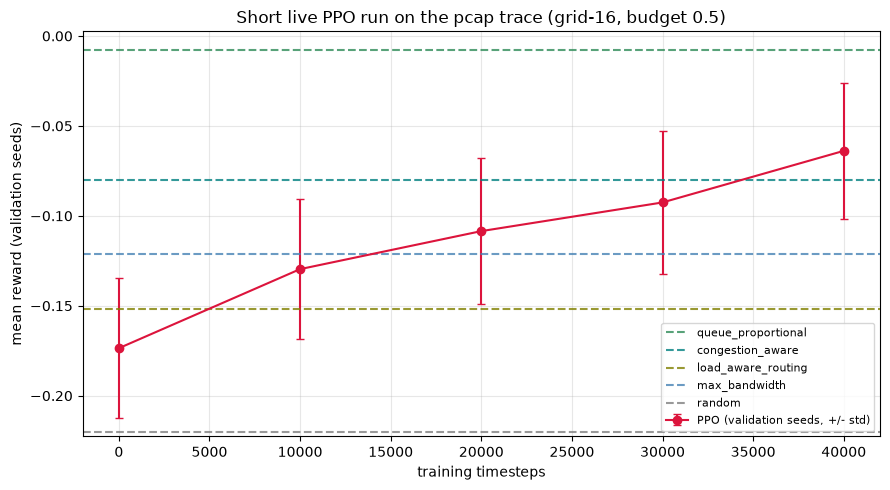

In [7]:
rng = np.random.default_rng(0)
live_baselines = {}
for name, fn in POLICIES.items():
    m, s = rollout(native_env, lambda e, o, fn=fn: fn(e, o, rng), val_seeds, steps=100)
    live_baselines[name] = m
    print(f"{name:20s} reward={m:+.3f} +/- {s:.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(live["timesteps"], live["reward_mean"], yerr=live["reward_std"], marker="o",
            color="crimson", capsize=3, label="PPO (validation seeds, +/- std)")
for name, color in styles.items():
    ax.axhline(live_baselines[name], ls="--", color=color, alpha=0.8, label=name)
ax.set_xlabel("training timesteps"); ax.set_ylabel("mean reward (validation seeds)")
ax.set_title("Short live PPO run on the pcap trace (grid-16, budget 0.5)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
start, end = live["reward_mean"].iloc[0], live["reward_mean"].iloc[-1]
beaten = sorted(n for n, v in live_baselines.items() if end > v)
not_beaten = sorted(n for n, v in live_baselines.items() if end <= v)
print(f"PPO moved from {start:+.3f} (untrained) to {end:+.3f} after {int(live['timesteps'].iloc[-1])} timesteps.")
print("Higher than:", beaten if beaten else "none")
print("Not higher than:", not_beaten if not_beaten else "none")
print("This is one short run with one seed: a demonstration, not a benchmark result.")

PPO moved from -0.174 (untrained) to -0.064 after 40000 timesteps.


Higher than: ['congestion_aware', 'load_aware_routing', 'max_bandwidth', 'min_bandwidth', 'random']
Not higher than: ['queue_proportional']
This is one short run with one seed: a demonstration, not a benchmark result.
